In [ ]:
!pip install -q qiskit qiskit-aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 71.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 114.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 105.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 5.8 MB/s eta 0:00:00


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

import qiskit

print("Qiskit version:", qiskit.__version__)

Qiskit version: 2.5.2


In [ ]:
# Load MNIST
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

# Select one test image
original = X_test[0]
label = y_test[0]

# Resize to 16×16
image = cv2.resize(
    original,
    (16, 16),
    interpolation=cv2.INTER_AREA
)

print("Original shape:", original.shape)
print("FRQI image shape:", image.shape)
print("Digit:", label)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Original shape: (28, 28)
FRQI image shape: (16, 16)
Digit: 7


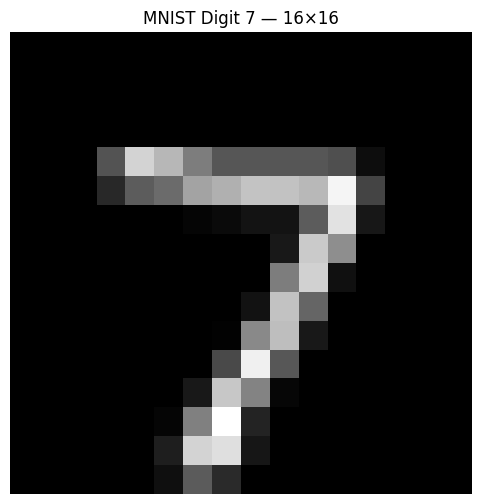

In [ ]:
plt.figure(figsize=(6, 6))

plt.imshow(
    image,
    cmap="gray"
)

plt.title(f"MNIST Digit {label} — 16×16")
plt.axis("off")

plt.show()

In [ ]:
# Normalize intensity to [0, 1]
normalized_image = image.astype(np.float64) / 255.0

# Convert intensity to angle
theta = normalized_image * (np.pi / 2)

# Flatten for pixel-wise encoding
theta_flat = theta.flatten()

print("Minimum pixel intensity:", image.min())
print("Maximum pixel intensity:", image.max())

print("Minimum angle:", theta_flat.min())
print("Maximum angle:", theta_flat.max())

Minimum pixel intensity: 0
Maximum pixel intensity: 252
Minimum angle: 0.0
Maximum angle: 1.5523163700090743


In [ ]:
image_size = 16

num_pixels = image_size * image_size

position_qubits_count = int(
    np.log2(num_pixels)
)

intensity_qubit = 0

position_qubits = list(
    range(1, position_qubits_count + 1)
)

total_qubits = (
    position_qubits_count + 1
)

print("Image size:", image_size, "×", image_size)
print("Number of pixels:", num_pixels)
print("Position qubits:", position_qubits_count)
print("Intensity qubits:", 1)
print("Total qubits:", total_qubits)
print("Position qubit indices:", position_qubits)

Image size: 16 × 16
Number of pixels: 256
Position qubits: 8
Intensity qubits: 1
Total qubits: 9
Position qubit indices: [1, 2, 3, 4, 5, 6, 7, 8]


In [ ]:
# ==========================================
# Create FRQI circuit
# ==========================================

qc = QuantumCircuit(total_qubits)

# Create equal superposition of all positions
for q in position_qubits:
    qc.h(q)

print("Position superposition created.")

print(qc.draw("text"))

Position superposition created.
          
q_0: ─────
     ┌───┐
q_1: ┤ H ├
     ├───┤
q_2: ┤ H ├
     ├───┤
q_3: ┤ H ├
     ├───┤
q_4: ┤ H ├
     ├───┤
q_5: ┤ H ├
     ├───┤
q_6: ┤ H ├
     ├───┤
q_7: ┤ H ├
     ├───┤
q_8: ┤ H ├
     └───┘


In [ ]:
# ==========================================
# FRQI Intensity Encoding
# ==========================================

def apply_frqi_rotation(
    qc,
    position_qubits,
    intensity_qubit,
    pixel_index,
    angle
):

    # Convert pixel index to binary
    binary = format(
        pixel_index,
        f"0{len(position_qubits)}b"
    )

    # Reverse because Qiskit uses
    # little-endian qubit ordering
    binary = binary[::-1]

    # Convert 0-controls into 1-controls
    for q, bit in zip(position_qubits, binary):

        if bit == "0":
            qc.x(q)

    # Controlled rotation
    qc.mcry(
        2 * angle,
        position_qubits,
        intensity_qubit
    )

    # Undo X gates
    for q, bit in zip(position_qubits, binary):

        if bit == "0":
            qc.x(q)


# Encode every pixel
for pixel_index, angle in enumerate(theta_flat):

    apply_frqi_rotation(
        qc,
        position_qubits,
        intensity_qubit,
        pixel_index,
        angle
    )

print("FRQI intensity encoding completed.")

FRQI intensity encoding completed.


In [ ]:
# ==========================================
# FRQI Resource Analysis
# ==========================================

print("FRQI Resource Analysis")
print("----------------------")

print("Image size     :", f"{image_size}×{image_size}")
print("Pixels         :", num_pixels)
print("Total qubits   :", qc.num_qubits)
print("Total gates    :", qc.size())
print("Circuit depth  :", qc.depth())

FRQI Resource Analysis
----------------------
Image size     : 16×16
Pixels         : 256
Total qubits   : 9
Total gates    : 72712
Circuit depth  : 50435


In [ ]:
# Draw the complete circuit
qc.draw("text", fold=100)

This cell output is too large and can only be displayed while logged in.


In [ ]:
# Generate FRQI Statevector
state = Statevector.from_instruction(qc)

print("Statevector dimension:", len(state))

Statevector dimension: 512


In [ ]:
# Probability normalization

probabilities = np.abs(state.data) ** 2

total_probability = np.sum(probabilities)

print("Total probability:", total_probability)

Total probability: 0.9999999999953312


In [ ]:
# Select a non-zero pixel

nonzero_indices = np.where(
    image.flatten() > 0
)[0]

pixel_index = nonzero_indices[0]

theta_original = theta_flat[pixel_index]

expected_probability = (
    np.sin(theta_original) ** 2
)

print("Pixel index:", pixel_index)
print(
    "Pixel intensity:",
    image.flatten()[pixel_index]
)
print("FRQI angle:", theta_original)
print(
    "Expected P(|1>):",
    expected_probability
)

Pixel index: 67
Pixel intensity: 82
FRQI angle: 0.5051188188124766
Expected P(|1>): 0.23417026637478194


In [ ]:
# Extract actual FRQI probability

actual_probability_1 = 0.0
actual_probability_total = 0.0

for index, amplitude in enumerate(state.data):

    probability = np.abs(amplitude) ** 2

    # --------------------------------------
    # Decode position using Qiskit's
    # little-endian convention
    # --------------------------------------

    position = 0

    for bit_number, q in enumerate(position_qubits):

        bit = (index >> q) & 1

        position += bit * (2 ** bit_number)

    # q0 = intensity qubit
    intensity_bit = index & 1

    # --------------------------------------
    # Select our pixel
    # --------------------------------------

    if position == pixel_index:

        actual_probability_total += probability

        if intensity_bit == 1:

            actual_probability_1 += probability


# Conditional probability
conditional_probability = (
    actual_probability_1 /
    actual_probability_total
)

print(
    "Actual conditional P(|1>):",
    conditional_probability
)

Actual conditional P(|1>): 0.2341702663748413


In [ ]:
# FRQI Encoding Verification

print("FRQI Encoding Verification")
print("---------------------------")

print(
    "Expected P(|1>):",
    expected_probability
)

print(
    "Actual P(|1>):  ",
    conditional_probability
)

print(
    "Absolute error: ",
    abs(
        expected_probability -
        conditional_probability
    )
)

FRQI Encoding Verification
---------------------------
Expected P(|1>): 0.23417026637478194
Actual P(|1>):   0.2341702663748413
Absolute error:  5.936917624183025e-14


In [ ]:
print("Conventional FRQI")
print("-----------------")
print("Qubits:", qc.num_qubits)
print("Gates :", qc.size())
print("Depth :", qc.depth())

Conventional FRQI
-----------------
Qubits: 9
Gates : 72712
Depth : 50435


In [ ]:
import pandas as pd
# Conventional FRQI — 100 Image Resource Evaluation

conventional_results = []

num_images = 100

for idx in range(num_images):

    # Prepare 16x16 image

    image_16 = cv2.resize(
        X_test[idx],
        (16, 16),
        interpolation=cv2.INTER_AREA
    )

    theta = (
        image_16.astype(np.float64) / 255.0
    ) * (np.pi / 2)

    theta_flat = theta.flatten()

    # FRQI parameters

    num_pixels = 16 * 16

    position_qubits_count = int(
        np.log2(num_pixels)
    )

    intensity_qubit = 0

    position_qubits = list(
        range(1, position_qubits_count + 1)
    )

    total_qubits = (
        position_qubits_count + 1
    )

    # Create circuit

    qc_temp = QuantumCircuit(
        total_qubits
    )

    # Position superposition
    for q in position_qubits:
        qc_temp.h(q)

    # Encode all pixels

    for pixel_index, angle in enumerate(theta_flat):

        binary = format(
            pixel_index,
            f"0{len(position_qubits)}b"
        )

        # Correct Qiskit little-endian ordering
        binary = binary[::-1]

        # Convert zero controls
        for q, bit in zip(
            position_qubits,
            binary
        ):

            if bit == "0":
                qc_temp.x(q)

        # Controlled rotation
        qc_temp.mcry(
            2 * angle,
            position_qubits,
            intensity_qubit
        )

        # Undo X gates
        for q, bit in zip(
            position_qubits,
            binary
        ):

            if bit == "0":
                qc_temp.x(q)

    # --------------------------------------------------------
    # Resource measurements
    # --------------------------------------------------------

    conventional_results.append({

        "Image": idx,

        "Digit": int(y_test[idx]),

        "Pixels": num_pixels,

        "Qubits": qc_temp.num_qubits,

        "Gates": qc_temp.size(),

        "Depth": qc_temp.depth()
    })

    print(
        f"Image {idx+1}/{num_images} completed",
        end="\r"
    )


conventional_results = pd.DataFrame(
    conventional_results
)

print("\n\nConventional FRQI evaluation completed.")

display(
    conventional_results.head()
)

Image 100/100 completed

Conventional FRQI evaluation completed.


,Image,Digit,Pixels,Qubits,Gates,Depth
0,0,7,256,9,72712,50435
1,1,2,256,9,72712,50435
2,2,1,256,9,72712,50435
3,3,0,256,9,72712,50435
4,4,4,256,9,72712,50435


In [ ]:
# Conventional FRQI — Average Resources

print("Conventional FRQI — 100 Images")
print("--------------------------------")

print(
    "Average qubits:",
    conventional_results["Qubits"].mean()
)

print(
    "Average gates:",
    conventional_results["Gates"].mean()
)

print(
    "Average circuit depth:",
    conventional_results["Depth"].mean()
)

Conventional FRQI — 100 Images
--------------------------------
Average qubits: 9.0
Average gates: 72712.0
Average circuit depth: 50435.0


In [ ]:
conventional_results.to_csv(
    "conventional_frqi_100_images.csv",
    index=False
)

print(
    "Saved: conventional_frqi_100_images.csv"
)

Saved: conventional_frqi_100_images.csv


In [ ]:
from google.colab import files

files.download(
    "conventional_frqi_100_images.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Checking Reconstruction Quality

In [ ]:
# Conventional FRQI Reconstruction

reconstructed_image = np.zeros(
    (16, 16),
    dtype=np.float64
)

for pixel_index in range(256):

    probability_1 = 0.0
    probability_total = 0.0

    for index, amplitude in enumerate(state.data):

        probability = np.abs(amplitude) ** 2

        position = 0

        for bit_number, q in enumerate(position_qubits):

            bit = (index >> q) & 1

            position += bit * (2 ** bit_number)

        intensity_bit = index & 1

        if position == pixel_index:

            probability_total += probability

            if intensity_bit == 1:
                probability_1 += probability

    if probability_total > 0:

        conditional_probability = (
            probability_1 /
            probability_total
        )

        theta_recovered = np.arcsin(
            np.sqrt(
                np.clip(
                    conditional_probability,
                    0,
                    1
                )
            )
        )

        intensity_recovered = (
            theta_recovered /
            (np.pi / 2)
        ) * 255

        y = pixel_index // 16
        x = pixel_index % 16

        reconstructed_image[y, x] = (
            intensity_recovered
        )

reconstructed_image = np.clip(
    reconstructed_image,
    0,
    255
)

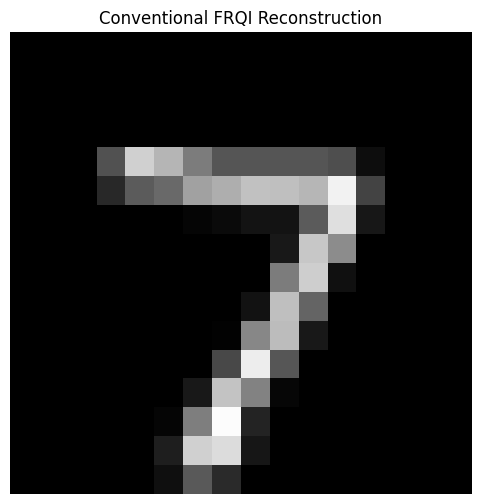

In [ ]:
# Display Conventional FRQI Reconstruction

plt.figure(figsize=(6, 6))

plt.imshow(
    reconstructed_image,
    cmap="gray",
    vmin=0,
    vmax=255
)

plt.title("Conventional FRQI Reconstruction")
plt.axis("off")

plt.show()

In [ ]:
# Conventional FRQI Reconstruction Metrics

from skimage.metrics import (
    mean_squared_error,
    peak_signal_noise_ratio,
    structural_similarity
)

mse_frqi = mean_squared_error(
    image,
    reconstructed_image
)

psnr_frqi = peak_signal_noise_ratio(
    image,
    reconstructed_image,
    data_range=255
)

ssim_frqi = structural_similarity(
    image,
    reconstructed_image,
    data_range=255
)

print("Conventional FRQI")
print("-----------------")
print("MSE  :", mse_frqi)
print("PSNR :", psnr_frqi, "dB")
print("SSIM :", ssim_frqi)

Conventional FRQI
-----------------
MSE  : 3.926341850637884e-22
PSNR : 262.1909225170112 dB
SSIM : 1.0


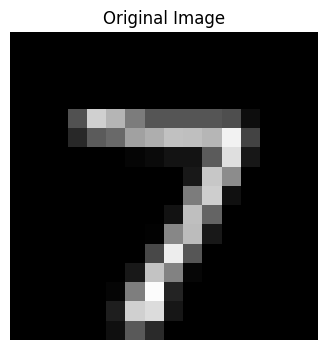

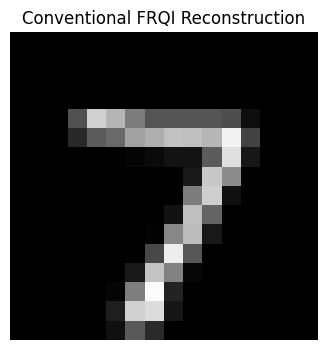

In [ ]:
# Conventional FRQI Comparison

plt.figure(figsize=(4,4))

plt.imshow(
    image,
    cmap="gray",
    vmin=0,
    vmax=255
)

plt.title("Original Image")
plt.axis("off")

plt.show()


plt.figure(figsize=(4,4))

plt.imshow(
    reconstructed_image,
    cmap="gray",
    vmin=0,
    vmax=255
)

plt.title("Conventional FRQI Reconstruction")
plt.axis("off")

plt.show()

In [ ]:
# ==========================================
# Conventional FRQI — 100 Image Evaluation
# Resources + Reconstruction Quality
# ==========================================

conventional_results = []

num_images = 100

for idx in range(num_images):

    # --------------------------------------
    # 1. Prepare 16×16 image
    # --------------------------------------

    image_16 = cv2.resize(
        X_test[idx],
        (16, 16),
        interpolation=cv2.INTER_AREA
    )

    # --------------------------------------
    # 2. Convert pixel intensities to angles
    # --------------------------------------

    theta = (
        image_16.astype(np.float64) / 255.0
    ) * (np.pi / 2)

    theta_flat = theta.flatten()

    # --------------------------------------
    # 3. FRQI parameters
    # --------------------------------------

    num_pixels = 16 * 16

    position_qubits_count = int(
        np.log2(num_pixels)
    )

    intensity_qubit = 0

    position_qubits = list(
        range(1, position_qubits_count + 1)
    )

    total_qubits = (
        position_qubits_count + 1
    )

    # --------------------------------------
    # 4. Create FRQI circuit
    # --------------------------------------

    qc_temp = QuantumCircuit(
        total_qubits
    )

    # Position superposition
    for q in position_qubits:
        qc_temp.h(q)

    # Encode all pixels
    for pixel_index, angle in enumerate(theta_flat):

        binary = format(
            pixel_index,
            f"0{len(position_qubits)}b"
        )

        binary = binary[::-1]

        # Convert zero controls
        for q, bit in zip(
            position_qubits,
            binary
        ):

            if bit == "0":
                qc_temp.x(q)

        # Controlled rotation
        qc_temp.mcry(
            2 * angle,
            position_qubits,
            intensity_qubit
        )

        # Undo X gates
        for q, bit in zip(
            position_qubits,
            binary
        ):

            if bit == "0":
                qc_temp.x(q)

    # --------------------------------------
    # 5. Obtain statevector
    # --------------------------------------

    statevector = Statevector.from_instruction(
        qc_temp
    )

    state = statevector.data

    # --------------------------------------
    # 6. Recover pixel intensities
    # --------------------------------------

    recovered_angles = []

    for pixel_index in range(num_pixels):

        # Intensity qubit = q0
        index_zero = 2 * pixel_index
        index_one = 2 * pixel_index + 1

        amplitude_zero = np.abs(
            state[index_zero]
        )

        amplitude_one = np.abs(
            state[index_one]
        )

        angle = np.arctan2(
            amplitude_one,
            amplitude_zero
        )

        recovered_angles.append(angle)

    recovered_angles = np.array(
        recovered_angles
    )

    # --------------------------------------
    # 7. Convert angles back to intensities
    # --------------------------------------

    recovered_pixels = (
        recovered_angles / (np.pi / 2)
    ) * 255.0

    recovered_pixels = np.clip(
        recovered_pixels,
        0,
        255
    )

    reconstructed = recovered_pixels.reshape(
        16, 16
    )

    # --------------------------------------
    # 8. Image-quality metrics
    # --------------------------------------

    mse = mean_squared_error(
        image_16,
        reconstructed
    )

    psnr = peak_signal_noise_ratio(
        image_16,
        reconstructed,
        data_range=255
    )

    ssim = structural_similarity(
        image_16,
        reconstructed,
        data_range=255
    )

    # --------------------------------------
    # 9. Store results
    # --------------------------------------

    conventional_results.append({

        "Image": idx,
        "Digit": int(y_test[idx]),

        "Pixels": num_pixels,

        "Qubits": qc_temp.num_qubits,

        "Gates": qc_temp.size(),

        "Depth": qc_temp.depth(),

        "MSE": mse,

        "PSNR": psnr,

        "SSIM": ssim
    })

    print(
        f"Image {idx + 1}/{num_images} completed",
        end="\r"
    )

print("\n\nConventional FRQI evaluation completed.")

conventional_results = pd.DataFrame(
    conventional_results
)

display(
    conventional_results.head()
)

Image 100/100 completed

Conventional FRQI evaluation completed.


,Image,Digit,Pixels,Qubits,Gates,Depth,MSE,PSNR,SSIM
0,0,7,256,9,72712,50435,3.926053e-22,262.191242,1.0
1,1,2,256,9,72712,50435,3.924772e-22,262.192660,1.0
2,2,1,256,9,72712,50435,3.951145e-22,262.163574,1.0
3,3,0,256,9,72712,50435,3.719014e-22,262.426525,1.0
4,4,4,256,9,72712,50435,3.828199e-22,262.300859,1.0


In [ ]:
# ==========================================
# Conventional FRQI — 100 Image Average
# ==========================================

conventional_average = pd.DataFrame([{

    "Representation": "Conventional FRQI",

    "Elements": conventional_results["Pixels"].mean(),

    "Qubits": conventional_results["Qubits"].mean(),

    "Gates": conventional_results["Gates"].mean(),

    "Depth": conventional_results["Depth"].mean(),

    "MSE": conventional_results["MSE"].mean(),

    "PSNR": conventional_results["PSNR"].mean(),

    "SSIM": conventional_results["SSIM"].mean()

}])

display(conventional_average)

,Representation,Elements,Qubits,Gates,Depth,MSE,PSNR,SSIM
0,Conventional FRQI,256.0,9.0,72712.0,50435.0,3.839699e-22,262.289269,1.0
